In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('Libraries loaded')

Libraries loaded


### Join the supervised stressed_state label onto the unsupervised archetype panel

This notebook continues the archetype series (after `03_balanced_clustering.ipynb`) by joining the supervised `stressed_state` label onto the labelled panel. Each active looping day gets its archetype (RQ1/RQ2) and whether it was a stressed day (from the supervised pipeline in `../whale-risk-supervised/`, RQ3). The archetypes were built without ever seeing the stress label, so the overlap is an independent cross-check of the two methods as well as a way to risk-grade the archetypes.

In [2]:
arch = pd.read_csv("panel_archetypes.csv", parse_dates=["date"])
lab = pd.read_csv("../whale-risk-supervised/whale_features_labeled.csv", parse_dates=["date"])

panel = arch.merge(
    lab[["whale_id", "date", "stressed_state"]],
    on=["whale_id", "date"],
    how="left",
)

matched = panel["stressed_state"].notna().sum()
print(f"{matched} of {len(panel)} archetype days matched a stressed_state label")
assert matched == len(panel), "some archetype days did not match a stressed_state label"
print(f"overall stressed share on active looping days: {panel['stressed_state'].mean() * 100:.1f}%")

2070 of 2070 archetype days matched a stressed_state label
overall stressed share on active looping days: 32.9%


Joined on `whale_id` and `date`, both shared across the two pipelines. All **2,070** active looping days (24 whales) find a label, so nothing is dropped. Overall **32.9%** (682/2,070) of days are flagged `stressed_state=1` under the per-whale model label. This is the baseline the per-archetype rates are compared against.

### Stressed share by archetype

In [3]:
ARCH_ORDER = ["moderate leverage", "high-LTV hold", "stale / light loop", "idle / outlier"]

by_arch = (
    panel.groupby("cluster_name")["stressed_state"]
    .agg(days="size", stressed_days="sum", stressed_pct="mean")
)
by_arch["stressed_pct"] = (by_arch["stressed_pct"] * 100).round(1)
by_arch = by_arch.reindex([a for a in ARCH_ORDER if a in by_arch.index])

panel.to_csv("panel_archetypes_stressed.csv", index=False)
by_arch

,days,stressed_days,stressed_pct
cluster_name,,,
moderate leverage,868,252,29.0
high-LTV hold,364,283,77.7
stale / light loop,734,130,17.7
idle / outlier,104,17,16.3


**Stressed share by archetype (per-whale label):**

| Archetype | Days | Stressed | % |
|---|---|---|---|
| high-LTV hold | 364 | 283 | **77.7** |
| moderate leverage | 868 | 252 | 29.0 |
| stale / light loop | 734 | 130 | 17.7 |
| idle / outlier | 104 | 17 | **16.3** |

Stress grades with leverage on the per-whale label. High-LTV hold leads at 77.7% (283/364 days) — these are each whale's most stressed, max-LTV tail; stale / light loop is lowest at 17.7% (130/734 days) because those days sit at lower LTV (mean 0.515) with a shallow per-whale stress tail (chiefly W-11 at 0% and the Aave whales W-18/W-19/W-24). The archetypes were built without the stress label, so the overlap is an independent cross-check.

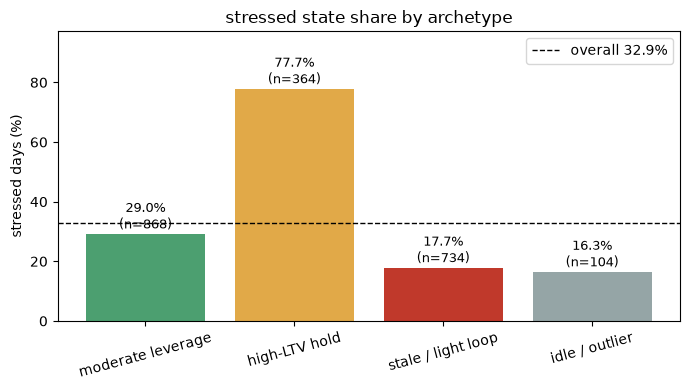

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"moderate leverage": "#4c9f70", "high-LTV hold": "#e1a948",
          "stale / light loop": "#c0392b", "idle / outlier": "#95a5a6"}
bars = ax.bar(by_arch.index, by_arch["stressed_pct"],
              color=[colors.get(a, "#888") for a in by_arch.index])
overall = panel["stressed_state"].mean() * 100
ax.axhline(overall, ls="--", c="k", lw=1, label=f"overall {overall:.1f}%")
for b, pct, n in zip(bars, by_arch["stressed_pct"], by_arch["days"]):
    ax.text(b.get_x() + b.get_width() / 2, pct + 0.6, f"{pct:.1f}%\n(n={n})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("stressed days (%)")
ax.set_title("stressed state share by archetype")
ax.set_ylim(0, max(by_arch["stressed_pct"]) * 1.25)
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Absolute health-factor stress measure (adopted as primary)

The per-whale label grades each whale against its own worst days, which is a within-whale view rather than a fair comparison between archetypes. Here we judge every whale on the same absolute buffer (lower health factor, closer to liquidation, counts as stressed) and adopt this as the cross-archetype risk measure, saved as `stressed_abs` (health factor < 1.05) alongside the panel. A few buffers are shown so the result does not hinge on one magic number.

In [5]:
chk = panel.merge(lab[["whale_id", "date", "health_factor"]], on=["whale_id", "date"], how="left")
panel["health_factor"] = chk["health_factor"].to_numpy()

# absolute, cross-whale stress measure: within 5% of liquidation (health factor < 1.05)
ABS_HF = 1.05
panel["stressed_abs"] = (panel["health_factor"] < ABS_HF).astype(int)
panel.to_csv("panel_archetypes_stressed.csv", index=False)

cmp = pd.DataFrame({"per-whale label %": by_arch["stressed_pct"]})
for thr in [1.05, 1.10, 1.15]:
    rate = (
        panel.assign(s=(panel["health_factor"] < thr).astype(int))
        .groupby("cluster_name")["s"].mean() * 100
    ).round(1)
    cmp[f"HF<{thr} %"] = rate
cmp.reindex(ARCH_ORDER)

,per-whale label %,HF<1.05 %,HF<1.1 %,HF<1.15 %
cluster_name,,,,
moderate leverage,29.0,29.0,43.8,59.6
high-LTV hold,77.7,77.7,92.3,100.0
stale / light loop,17.7,17.7,38.1,49.7
idle / outlier,16.3,16.3,24.0,26.9


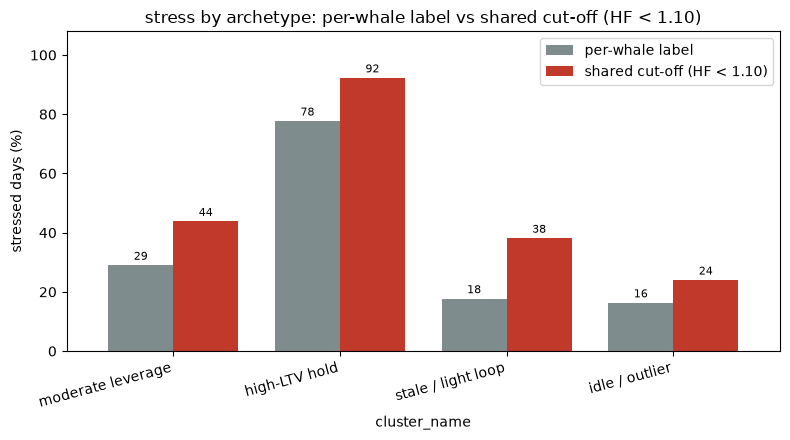

In [6]:
plot_df = cmp.reindex(ARCH_ORDER)[["per-whale label %", "HF<1.1 %"]]

ax = plot_df.plot(kind="bar", figsize=(8, 4.5), color=["#7f8c8d", "#c0392b"], width=0.78)
ax.set_ylabel("stressed days (%)")
ax.set_title("stress by archetype: per-whale label vs shared cut-off (HF < 1.10)")
ax.legend(["per-whale label", "shared cut-off (HF < 1.10)"])
ax.set_ylim(0, 108)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Absolute HF stress by archetype:**

| Archetype | HF&lt;1.05 % | HF&lt;1.10 % | HF&lt;1.15 % |
|---|---|---|---|
| high-LTV hold | **77.7** | 92.3 | 100.0 |
| moderate leverage | 29.0 | 43.8 | 59.6 |
| stale / light loop | 17.7 | 38.1 | 49.7 |
| idle / outlier | **16.3** | 24.0 | 26.9 |

On a shared cut-off the ordering tracks raw leverage: high-LTV hold is highest at every buffer (77.7% at HF&lt;1.05, 100% at HF&lt;1.15), moderate sits mid (29–60%), stale / light loop is next (17.7% at HF&lt;1.05), and idle stays lowest (~16–27%). Profile-based naming aligns archetype labels with this risk ranking. `stressed_abs` (HF&lt;1.05) is saved as the primary cross-archetype risk measure.

### Moderate leverage split by LTV (preview)

**Moderate leverage sub-split (868 days total):**

| LTV band | Days | Stressed | % |
|---|---|---|---|
| LTV &lt; 0.6 | 253 | 0 | **0.0** |
| LTV ≥ 0.6 | 615 | 252 | **41.0** |

Whale mix per band:
- **LTV &lt; 0.6:** W-11 (211 days), W-3 (27), W-14 (8), W-16 (7) — lower-leverage / partial-unwind days.
- **LTV ≥ 0.6:** W-11 (133), W-3 (72), W-7 (57), W-10 (57), W-14 (53), W-1 (37), W-9 (23), W-13 (22), W-21 (19), W-8 (17), W-24 (15), W-18 (20), W-19 (14), W-16 (13), plus the remaining Aave whales — mid–high LTV active rebalancers.

The split separates W-11's lighter-LTV stale days from the W-7/W-15/W-3 active-rebalance core. The higher band carries all of the archetype's stress (41%), while the lower band has none.

In [7]:
mod = panel[panel["cluster_name"] == "moderate leverage"].copy()
mod["ltv_band"] = np.where(mod["ltv"] >= 0.6, "LTV >= 0.6", "LTV < 0.6")

mod_split = (
    mod.groupby("ltv_band")["stressed_state"]
    .agg(days="size", stressed_days="sum", stressed_pct="mean")
)
mod_split["stressed_pct"] = (mod_split["stressed_pct"] * 100).round(1)
print(mod_split.to_string())
print("\nwhale mix per band:")
print(mod.groupby("ltv_band")["whale_id"].value_counts().unstack(fill_value=0).to_string())

            days  stressed_days  stressed_pct
ltv_band                                     
LTV < 0.6    253              0           0.0
LTV >= 0.6   615            252          41.0

whale mix per band:
whale_id    W-1  W-10  W-11  W-13  W-14  W-15  W-16  W-17  W-18  W-19  W-2  W-20  W-21  W-22  W-23  W-24  W-3  W-4  W-5  W-6  W-7  W-8  W-9
ltv_band                                                                                                                                   
LTV < 0.6     0     0   211     0     8     0     7     0     0     0    0     0     0     0     0     0   27    0    0    0    0    0    0
LTV >= 0.6   37    57   133    22    53     8    13     1    20    14    1     7    19     6     8    15   72   14    9    9   57   17   23


### Next steps

- Calibrate the absolute health-factor threshold to something principled (observed liquidation events or each protocol's liquidation threshold) rather than the current hand-picked 5% buffer. Needs liquidation-event data.
- Use `strategist_type` and `moderate_sub` from `03` for whale-level mixed vs moderate-core splits.
- Split moderate leverage (`LTV < 0.6` vs `>= 0.6`) to separate W-3 partial-unwind days from W-7/W-15 mid-LTV holders.
- Cross stressed days with `days_since_rebalance` per archetype to test the RQ3 mechanism (stress driven by current LTV, rebalancing by accumulated LTV history).